# Independent Soft Actor-Critic (SAC) baseline

This notebook trains **one SAC policy per building** on the local CityLearn June dataset and evaluates it on held-out validation and test intervals.

**Dataset scope:** 720 hourly steps covering **June 1–30 only**. Results do **not** support cross-season generalization claims.

Carbon-aware and fairness rewards are reserved for later MARLISA experiments and are **not** used here.

## Reward: electricity + thermal discomfort

`central_agent=False` gives each building its own observations, actions, replay buffer, actor, and critics.

The Independent SAC baseline optimizes:

$$
r_i(t) = -\lambda_E \hat{E}_i^+(t) - \lambda_D D_i(t)
$$

where $\hat{E}_i^+(t) = \max(E_i(t), 0) / E_{\mathrm{scale}}$ and $D_i(t)$ is an occupancy-gated comfort violation outside the comfort band, using the schema ComfortReward settings (`band=1.0`, `lower_exponent=2.0`, `higher_exponent=3.0`).

Default normalization scales are $E_{\mathrm{scale}}=10$ kWh and $D_{\mathrm{scale}}=4$. Default weights are $\lambda_E=\lambda_D=1$.

This replaces the previous electricity-only CityLearn `IndependentSACReward`. Do not reuse older electricity-only SAC outputs as evidence for this revised objective.

## Train / validation / test split

| Split | Dates | Inclusive time steps | CityLearn transitions |
|---|---|---|---|
| Train | June 1–20 | 0–479 | 479 |
| Validation | June 21–25 | 480–599 | 119 |
| Test | June 26–30 | 600–719 | 119 |

Training, replay-buffer collection, observation-normalization fitting, and model selection use **train/validation only**. Test KPIs are reported after checkpoint selection.

Buildings use `LSTMDynamicsBuilding` with lookback 12. Validation/test evaluation can prepend a 12-step warm-up that is not scored.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset_splits import DEFAULT_SEEDS, SPLITS, TEST_SPLIT
from src.run_independent_sac import (
    aggregate_seed_results,
    evaluate_independent_sac,
    run_independent_sac,
)

SCHEMA = PROJECT_ROOT / 'notebooks' / 'data' / 'schema.json'
OUTPUT_DIRECTORY = PROJECT_ROOT / 'outputs' / 'independent_sac'
RBC_TEST_KPI_PATH = PROJECT_ROOT / 'outputs' / 'rbc' / 'test_kpis.csv'

print(f'Project root: {PROJECT_ROOT}')
print(f'Schema exists: {SCHEMA.is_file()}')
for name, split in SPLITS.items():
    print(name, split.as_dict())

Project root: D:\NUS\CS5446 Reinforcement Learning\cs5446_project
Schema exists: True
train {'name': 'train', 'start_time_step': 0, 'end_time_step': 479, 'start_date': 'June 1', 'end_date': 'June 20', 'n_time_steps': 480, 'n_transitions': 479}
validation {'name': 'validation', 'start_time_step': 480, 'end_time_step': 599, 'start_date': 'June 21', 'end_date': 'June 25', 'n_time_steps': 120, 'n_transitions': 119}
test {'name': 'test', 'start_time_step': 600, 'end_time_step': 719, 'start_date': 'June 26', 'end_date': 'June 30', 'n_time_steps': 120, 'n_transitions': 119}


## Experiment configuration

Default training budget: **50 training episodes** on the train split, with periodic validation every 5 episodes. Validation/test episodes are **not** counted as training.

Verified CityLearn SAC behavior for this setup:
- exploration while `agent.time_step <= end_exploration_time_step`
- standardization + gradient updates when `agent.time_step >= standardize_start_time_step` and the replay buffer is large enough
- replay buffers and network parameters persist across episodes
- `deterministic_finish=False` during training; evaluation is a separate deterministic function

Effective defaults for 480-hour training episodes: `end_exploration_time_step=478`, `standardize_start_time_step=479`.

Start with one seed to verify the pipeline. Use all five seeds `[42, 123, 2024, 2025, 2026]` only for the full experiment.

In [2]:
SEED = 42
TRAINING_EPISODES = 50
VALIDATION_EVERY = 5
DISCOMFORT_THRESHOLD = 0.20

# Set True only after the single-seed pipeline check succeeds.
RUN_ALL_SEEDS = False
SEEDS = list(DEFAULT_SEEDS) if RUN_ALL_SEEDS else [SEED]

SAC_PARAMETERS = {
    'hidden_dimension': (256, 256),
    'discount': 0.99,
    'tau': 0.005,
    'alpha': 0.2,
    'learning_rate': 3e-4,
    'batch_size': 256,
    'replay_buffer_capacity': 100_000,
    'action_scaling_coefficient': 0.5,
    'reward_scaling': 5.0,
    'update_per_time_step': 1,
    'standardize_start_time_step': 479,
    'end_exploration_time_step': 478,
    'lambda_electricity': 1.0,
    'lambda_discomfort': 1.0,
    'validation_every': VALIDATION_EVERY,
    'discomfort_threshold': DISCOMFORT_THRESHOLD,
}

pd.Series({'seeds': SEEDS, 'episodes': TRAINING_EPISODES, **SAC_PARAMETERS})

seeds                                [42]
episodes                               50
hidden_dimension               (256, 256)
discount                             0.99
tau                                 0.005
alpha                                 0.2
learning_rate                      0.0003
batch_size                            256
replay_buffer_capacity             100000
action_scaling_coefficient            0.5
reward_scaling                        5.0
update_per_time_step                    1
standardize_start_time_step           479
end_exploration_time_step             478
lambda_electricity                    1.0
lambda_discomfort                     1.0
validation_every                        5
discomfort_threshold                  0.2
dtype: object

## Train, validate, and test

This cell launches the refactored pipeline. It saves inference-only checkpoints, validation KPI history, model-selection metadata, and held-out test KPIs under `outputs/independent_sac/seed_<seed>/`.

Model selection uses validation only: prefer discomfort ≤ threshold, then minimize electricity; otherwise fall back to least discomfort.

**Before a full 50-episode run**, prefer the CLI smoke test:

```powershell
conda activate citylearn
python -m pytest tests/test_sac_reward.py tests/test_sac_splits.py tests/test_sac_smoke.py -v
```

In [3]:
results_by_seed = {}

for seed in SEEDS:
    print(f'\n=== Training seed {seed} ===')
    results_by_seed[seed] = run_independent_sac(
        schema=SCHEMA,
        output_directory=OUTPUT_DIRECTORY,
        episodes=TRAINING_EPISODES,
        random_seed=seed,
        reward='electricity_discomfort',
        **SAC_PARAMETERS,
    )
    selection = results_by_seed[seed]['model_selection']
    print('Model selection:', selection)
    print('Output:', results_by_seed[seed]['output_directory'])

result = results_by_seed[SEEDS[0]]


=== Training seed 42 ===
[SAC] seed=42 | train episodes=50 | split=0-479 (479 transitions/episode)
[SAC] end_exploration=478 | standardize_start=479 | reward=ElectricityDiscomfortSACReward
[SAC] episode 1/50 training...
[SAC] episode 1/50 done | mean_reward=-7.9351 | sum_reward=-11402.77 | env_steps=479 | grad_updates=3 | agent_t=479
[SAC] episode 2/50 training...
[SAC] episode 2/50 done | mean_reward=-3.5168 | sum_reward=-5053.64 | env_steps=958 | grad_updates=1440 | agent_t=958
[SAC] episode 3/50 training...
[SAC] episode 3/50 done | mean_reward=-1.2740 | sum_reward=-1830.70 | env_steps=1437 | grad_updates=2877 | agent_t=1437
[SAC] episode 4/50 training...
[SAC] episode 4/50 done | mean_reward=-0.6180 | sum_reward=-888.02 | env_steps=1916 | grad_updates=4314 | agent_t=1916
[SAC] episode 5/50 training...
[SAC] episode 5/50 done | mean_reward=-0.7950 | sum_reward=-1142.43 | env_steps=2395 | grad_updates=5751 | agent_t=2395
[SAC] episode 5/50 validating on held-out split...
[SAC] valid

## Training curves and validation history

Training rewards are learning curves only. They are **not** held-out performance.

,episode,phase,split,mean_reward,sum_reward,transitions,environment_steps,gradient_updates,agent_time_step
0,1,training,train,-7.935,-11402.771,479,479,3,479
1,2,training,train,-3.517,-5053.641,479,958,1440,958
2,3,training,train,-1.274,-1830.701,479,1437,2877,1437
3,4,training,train,-0.618,-888.021,479,1916,4314,1916
4,5,training,train,-0.795,-1142.433,479,2395,5751,2395
5,6,training,train,-0.514,-738.314,479,2874,7188,2874
6,7,training,train,-0.429,-615.772,479,3353,8625,3353
7,8,training,train,-0.394,-566.735,479,3832,10062,3832
8,9,training,train,-0.407,-585.135,479,4311,11499,4311
9,10,training,train,-0.387,-556.652,479,4790,12936,4790


,episode,checkpoint_path,district_electricity_consumption_kwh,district_discomfort_proportion,district_carbon_emissions_kgco2,district_electricity_cost,district_daily_peak_kwh,district_ramping_kwh
0,5,D:\NUS\CS5446 Reinforcement Learning\cs5446_pr...,365.645,0.308,168.681,11.542,8.339,75.715
1,10,D:\NUS\CS5446 Reinforcement Learning\cs5446_pr...,388.136,0.213,180.043,12.127,8.742,82.492
2,15,D:\NUS\CS5446 Reinforcement Learning\cs5446_pr...,385.969,0.278,178.762,12.061,8.585,80.289
3,20,D:\NUS\CS5446 Reinforcement Learning\cs5446_pr...,386.859,0.201,179.407,12.149,8.622,81.358
4,25,D:\NUS\CS5446 Reinforcement Learning\cs5446_pr...,391.616,0.190,181.589,12.316,8.547,82.609
5,30,D:\NUS\CS5446 Reinforcement Learning\cs5446_pr...,391.417,0.203,181.213,12.318,8.505,82.818
6,35,D:\NUS\CS5446 Reinforcement Learning\cs5446_pr...,398.961,0.223,184.510,12.506,8.465,81.211
7,40,D:\NUS\CS5446 Reinforcement Learning\cs5446_pr...,395.089,0.219,182.660,12.385,8.417,82.490
8,45,D:\NUS\CS5446 Reinforcement Learning\cs5446_pr...,398.776,0.226,184.414,12.533,8.511,82.686
9,50,D:\NUS\CS5446 Reinforcement Learning\cs5446_pr...,394.454,0.213,182.654,12.375,8.537,83.700


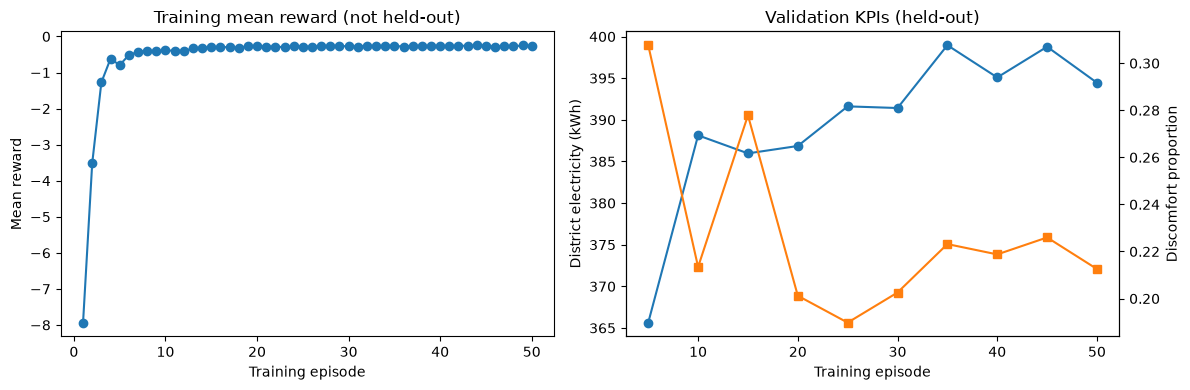

In [4]:
training_rewards = result['training_rewards']
validation_history = result['validation_history']

display(training_rewards.round(3))
display(validation_history.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(training_rewards['episode'], training_rewards['mean_reward'], marker='o')
axes[0].set_title('Training mean reward (not held-out)')
axes[0].set_xlabel('Training episode')
axes[0].set_ylabel('Mean reward')

axes[1].plot(
    validation_history['episode'],
    validation_history['district_electricity_consumption_kwh'],
    marker='o',
    label='electricity kWh',
)
ax2 = axes[1].twinx()
ax2.plot(
    validation_history['episode'],
    validation_history['district_discomfort_proportion'],
    marker='s',
    color='C1',
    label='discomfort',
)
axes[1].set_title('Validation KPIs (held-out)')
axes[1].set_xlabel('Training episode')
axes[1].set_ylabel('District electricity (kWh)')
ax2.set_ylabel('Discomfort proportion')
fig.tight_layout()
plt.show()

## Held-out test KPIs

Primary KPIs below are **raw scored-interval** values from the selected validation checkpoint evaluated on June 26–30.

CityLearn legacy `evaluate()` electricity/carbon/cost metrics are baseline-normalized ratios; discomfort is an occupied-time proportion. Prefer the raw scored KPIs for interpretation.

In [5]:
test_result = result['test_result']
assert test_result is not None, 'Test evaluation was skipped'

test_kpis = test_result['kpis']
display(test_kpis.round(3))

district = test_kpis.query("name == 'District'").set_index('cost_function')['value']
print('Held-out test district summary:')
print(district.round(3))

,name,level,cost_function,value,scored_local_start,scored_local_end,normalization_note
0,Building_1,building,electricity_consumption_kwh,138.977,12,130,raw_scored_interval
1,Building_1,building,carbon_emissions_kgco2,61.041,12,130,raw_scored_interval
2,Building_1,building,electricity_cost,4.441,12,130,raw_scored_interval
3,Building_1,building,discomfort_proportion,0.559,12,130,raw_scored_interval
4,Building_1,building,discomfort_cold_proportion,0.051,12,130,raw_scored_interval
5,Building_1,building,discomfort_hot_proportion,0.508,12,130,raw_scored_interval
6,Building_1,building,daily_peak_kwh,4.185,12,130,raw_scored_interval
7,Building_1,building,ramping_kwh,49.291,12,130,raw_scored_interval
8,Building_2,building,electricity_consumption_kwh,101.093,12,130,raw_scored_interval
9,Building_2,building,carbon_emissions_kgco2,44.620,12,130,raw_scored_interval


Held-out test district summary:
cost_function
electricity_consumption_kwh    401.450
carbon_emissions_kgco2         181.328
electricity_cost                12.924
discomfort_proportion            0.272
daily_peak_kwh                  11.402
ramping_kwh                     95.737
Name: value, dtype: float64


## Building-level comfort diagnostics

The physical-state log includes indoor temperature, cooling setpoint, occupancy, and binary comfort violations on scored steps.

,mean_indoor,mean_setpoint,violation_rate,mean_net_electricity
building,,,,
Building_1,24.692,23.749,0.126,1.110
Building_2,25.545,24.852,0.034,0.849
Building_3,24.317,24.360,0.000,1.402


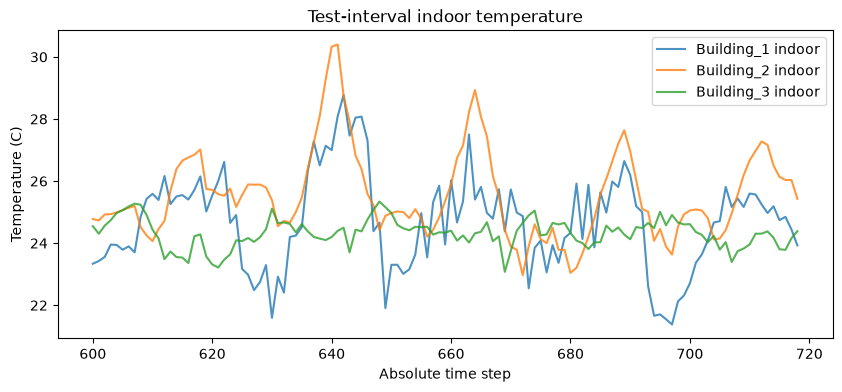

In [6]:
physical = test_result['physical_state'].query('scored')
comfort = (
    physical.groupby('building')
    .agg(
        mean_indoor=('indoor_dry_bulb_temperature', 'mean'),
        mean_setpoint=('cooling_set_point', 'mean'),
        violation_rate=('comfort_violation', 'mean'),
        mean_net_electricity=('net_electricity_consumption', 'mean'),
    )
    .round(3)
)
display(comfort)

fig, ax = plt.subplots(figsize=(10, 4))
for building_name, building_frame in physical.groupby('building'):
    ax.plot(
        building_frame['time_step_absolute'],
        building_frame['indoor_dry_bulb_temperature'],
        label=f'{building_name} indoor',
        alpha=0.8,
    )
ax.set_title('Test-interval indoor temperature')
ax.set_xlabel('Absolute time step')
ax.set_ylabel('Temperature (C)')
ax.legend()
plt.show()

## Compare with BasicRBC on the same test interval

Only compare SAC and RBC on the **same test split** (steps 600–719). If an RBC test-interval KPI file is not available yet, this cell explains what is missing instead of inventing values.

Existing `outputs/rbc/` results from the full June episode are **not** a valid same-interval comparison unless regenerated on the test split.

In [7]:
if RBC_TEST_KPI_PATH.is_file():
    rbc_test = pd.read_csv(RBC_TEST_KPI_PATH)
    comparison = (
        test_kpis.query("name == 'District'")[['cost_function', 'value']]
        .rename(columns={'value': 'independent_sac'})
        .merge(
            rbc_test.query("name == 'District'")[['cost_function', 'value']]
            .rename(columns={'value': 'basic_rbc'}),
            on='cost_function',
            how='inner',
        )
    )
    display(comparison.round(3))
else:
    print(
        'No RBC test-split KPI file found at',
        RBC_TEST_KPI_PATH,
        '\nGenerate BasicRBC on steps 600-719 before comparing on the held-out interval.',
    )
    print('SAC held-out district KPIs:')
    display(test_kpis.query("name == 'District'").round(3))

No RBC test-split KPI file found at D:\NUS\CS5446 Reinforcement Learning\cs5446_project\outputs\rbc\test_kpis.csv 
Generate BasicRBC on steps 600-719 before comparing on the held-out interval.
SAC held-out district KPIs:


,name,level,cost_function,value,scored_local_start,scored_local_end,normalization_note
24,District,district,electricity_consumption_kwh,401.450,12,130,raw_scored_interval
25,District,district,carbon_emissions_kgco2,181.328,12,130,raw_scored_interval
26,District,district,electricity_cost,12.924,12,130,raw_scored_interval
27,District,district,discomfort_proportion,0.272,12,130,raw_scored_interval
28,District,district,daily_peak_kwh,11.402,12,130,raw_scored_interval
29,District,district,ramping_kwh,95.737,12,130,raw_scored_interval


## Multi-seed aggregation

When `RUN_ALL_SEEDS=True`, aggregate test KPIs with mean and standard deviation while retaining per-seed files.

In [8]:
if RUN_ALL_SEEDS:
    summary = aggregate_seed_results(OUTPUT_DIRECTORY, seeds=tuple(SEEDS))
    display(summary.round(3))
else:
    print('Single-seed development run. Set RUN_ALL_SEEDS=True for mean/std aggregation.')

Single-seed development run. Set RUN_ALL_SEEDS=True for mean/std aggregation.


## How to interpret this baseline

- Check that validation curves are used for model selection, not test KPIs.
- Confirm electricity and discomfort both appear in the reward-component logs.
- Treat CityLearn normalized legacy KPIs as ratios, not raw percentages.
- Do not claim convergence from a short smoke run.
- Do not claim seasonal generalization from this June-only dataset.

### Recommended full experiment command

```powershell
conda activate citylearn
python src/run_independent_sac.py --episodes 50 --seeds 42 123 2024 2025 2026
```